# 01 - Exploratory Data Analysis
University Helpdesk Ticket Classifier. Dataset inspection before modelling: size, missing values, duplicates, class balance, text length, noise, and preprocessing before/after.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 140)
from src.utils import load_config
cfg = load_config()

## 1. Raw data

In [2]:
raw = pd.read_csv(cfg['paths']['raw_data'])
print(raw.shape)
raw.head(8)

(6052, 7)


,ticket_id,text,category,source,created_date,gen_kind,template_id
0,TKT103080,"Hello team, hall ticket is shownig debarred bcoz of attendance, I had a medical certificate. I already raised ticket #19384 but no respo...",Academics_Exams,web_form,2026-11-30,standard,core:Academics_Exams:26
1,TKT104741,To the helpdesk please fix the broken window and door lock of Hostel B-105? My exam is tomorrow! pls do the needful,Hostel_Facilities,email,2026-10-21,standard,core:Hostel_Facilities:12
2,TKT103519,THE STUDENT PORTAL PAGE HTTPS://FEES.KRMU.EDU.IN/PAY?REF=2242 IS NT LOADING AFTER LOGIN? THIS IS THE SECOND TIME I AM REPORTING THIS. PL...,LMS_Portal,web_form,2026-07-10,standard,core:LMS_Portal:13
3,TKT102299,"Hello, the library computers cannot connect to the internet, page does not load!",IT_WiFi,web_form,2026-07-04,standard,core:IT_WiFi:9
4,TKT101694,lan port in block e faculty cabin is not working? roll no: krm2025mba019. waiting for your response.,IT_WiFi,mobile_app,2026-08-27,standard,core:IT_WiFi:14
5,TKT103245,"Hi, website www.krmu.edu.in/hostel is showing HTTP 400 on the campus network but works on mobile data. It happened at 2 pm. Kindly resol...",IT_WiFi,web_form,2026-11-24,standard,core:IT_WiFi:18
6,TKT100476,mess timing for dinner should be extedned for students with late labs. i am a 5th semester student.,Hostel_Facilities,email,2026-11-30,standard,core:Hostel_Facilities:13
7,TKT102117,portal nt opening,LMS_Portal,email,2026-07-25,vague,vague:LMS_Portal:0


In [3]:
print('Missing text :', raw['text'].isna().sum())
print('Blank text   :', (raw['text'].fillna('').str.strip()=='').sum())
print('Exact duplicate rows:', raw.duplicated(subset=['text','category']).sum())
raw['category'].value_counts().to_frame('tickets')

Missing text : 6
Blank text   : 12
Exact duplicate rows: 198


,tickets
category,
IT_WiFi,1544
Academics_Exams,1370
Hostel_Facilities,1105
Fees_Accounts,1052
LMS_Portal,981


Generation types (only available because the data is synthetic): standard, ambiguous (multi-intent), vague, and a small share of deliberately mis-filed labels.

In [4]:
pd.crosstab(raw['category'], raw['gen_kind'])

gen_kind,ambiguous,ambiguous+mislabel,standard,standard+mislabel,vague,vague+mislabel
category,,,,,,
Academics_Exams,128,0,1179,14,48,1
Fees_Accounts,136,0,855,18,43,0
Hostel_Facilities,96,2,945,13,49,0
IT_WiFi,135,4,1334,18,53,0
LMS_Portal,95,0,843,6,36,1


## 2. Cleaned splits

In [5]:
from src.data.load_dataset import load_processed
splits = {s: load_processed(s) for s in ['train','val','test']}
pd.DataFrame({s: d['category'].value_counts() for s, d in splits.items()})

,train,val,test
category,,,
IT_WiFi,890,190,191
Academics_Exams,794,171,170
Hostel_Facilities,640,137,138
Fees_Accounts,610,131,131
LMS_Portal,564,121,120


In [6]:
train = splits['train']
train['n_words'] = train['text'].str.split().str.len()
train.groupby('category')['n_words'].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Academics_Exams,794.0,20.0,5.4,2.0,17.0,20.0,23.8,40.0
Fees_Accounts,610.0,19.1,5.3,1.0,16.0,19.0,22.0,36.0
Hostel_Facilities,640.0,18.8,5.2,2.0,16.0,19.0,22.0,39.0
IT_WiFi,890.0,20.6,5.1,2.0,17.0,20.0,24.0,41.0
LMS_Portal,564.0,19.5,5.5,2.0,16.0,19.0,23.0,42.0


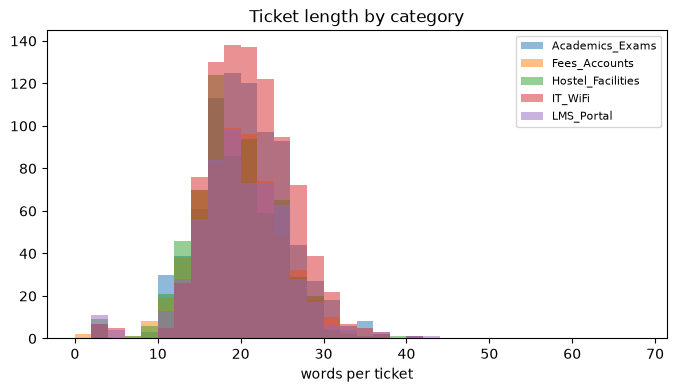

In [7]:
fig, ax = plt.subplots(figsize=(8,4))
for c, g in train.groupby('category'): ax.hist(g['n_words'], bins=range(0,70,2), alpha=.5, label=c)
ax.legend(fontsize=8); ax.set_xlabel('words per ticket'); ax.set_title('Ticket length by category'); plt.show()

## 3. Sample tickets per category

In [8]:
for c, g in train.groupby('category'):
    print(f'\n=== {c} ===')
    for t in g['text'].sample(4, random_state=1): print(' -', t)


=== Academics_Exams ===
 - Hall ticket is showing debarred because of attendance, I had a medical certificate I already raised ticket #45916 but no response. Waiting for your response.
 - exam centre allotted is wrong on my admit card, i am a regular student.
 - Migration certificate and transcript needed for higher studies. I already raised ticcket #89246 but no response. thx.
 - Hello team, credits for the MOOC course are not transferred to my academic record I already raised ticket #39128 but no response. Who should I contact?

=== Fees_Accounts ===
 - Hello team, fee due shows ₹ 12500 extra which I have already paid via NEFT. Please reply soon.
 - Good morning, fee due shows INR 1200 extra which I have already paid via NEFT. Kindly help.
 - Hi, the fee paid via UPI with rference TXN-879759 is nt updated in the ledger.
 - fee paid but portal shows unpaid and i cannot access my courses i already raised ticket #59995 but no response. - mr. priya verma

=== Hostel_Facilities ===
 - to

## 4. Noise inventory
How much of the text needs the preprocessing steps?

In [9]:
import re
t = train['text']
noise = {
  'contains URL': t.str.contains(r'https?://|www\.', regex=True).mean(),
  'contains e-mail': t.str.contains(r'@\w', regex=True).mean(),
  'contains phone': t.str.contains(r'\b[6-9]\d{9}\b|\+91', regex=True).mean(),
  'all lowercase': (t == t.str.lower()).mean(),
  'ALL UPPERCASE': (t == t.str.upper()).mean(),
  'repeated !!/??': t.str.contains(r'[!?]{2,}', regex=True).mean(),
  'emoji': t.str.contains('[\U0001F300-\U0001FAFF]', regex=True).mean(),
  'abbreviation (pls/acct/u/nt)': t.str.contains(r'\b(pls|acct|u|nt|bcoz|thx)\b', regex=True, case=False).mean()}
pd.Series(noise).map('{:.1%}'.format).to_frame('share of training tickets')

C:\Users\Aman Kumar Sharma\AppData\Local\Temp\ipykernel_27604\1582024946.py:11: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  'abbreviation (pls/acct/u/nt)': t.str.contains(r'\b(pls|acct|u|nt|bcoz|thx)\b', regex=True, case=False).mean()}


,share of training tickets
contains URL,5.5%
contains e-mail,4.1%
contains phone,6.4%
all lowercase,33.4%
ALL UPPERCASE,2.8%
repeated !!/??,4.0%
emoji,5.1%
abbreviation (pls/acct/u/nt),25.1%


## 5. Preprocessing before / after

In [10]:
train[['text','text_clean','text_light']].sample(6, random_state=7)

,text,text_clean,text_light
2631,"To the helpdesk, parking space near Block D is nt enough for two wheelers I am a 4th semester student. Need this fixed urgently. - Mr. V...",helpdesk parking space near block not wheeler 4th semester student need fix urgently mr varun verma,"To the helpdesk, parking space near Block D is nt enough for two wheelers I am a 4th semester student. Need this fixed urgently. - Mr. V..."
1587,"good morning, campus wifi portal is nt onening the login page, the captive page shows e-1878 this is krm2023bsc042 from 3rd semester. pl...",good morning campus wifi portal not onene login page captive page errorcodetoken studentidtoken 3rd semester reply soon,"good morning, campus wifi portal is nt onening the login page, the captive page shows e-1878 this is krm2023bsc042 from 3rd semester. pl..."
2712,"Good morning, re-evaluation result was supposed to come out by 22-10-2026 but nothing yet. This is KRM2022BCOM107 from 3rd semester. Who...",good morning evaluation result suppose come studentidtoken 3rd semester contact,"Good morning, re-evaluation result was supposed to come out by 22-10-2026 but nothing yet. This is KRM2022BCOM107 from 3rd semester. Who..."
3196,"to the helpdesk, my lms acct shows the previous sem courses instead of 4th sem. need this fixed urgently. thx, ms. aditya malhotra 😡",helpdesk lms account previous semester course instead 4th semester need fix urgently thank ms aditya malhotra,"to the helpdesk, my lms acct shows the previous sem courses instead of 4th sem. need this fixed urgently. thx, ms. aditya malhotra"
375,"good morning, parking space near block c is not enough for two wheelers. pls help",good morning parking space near block not wheeler help,"good morning, parking space near block c is not enough for two wheelers. pls help"
1963,"Hello, campus wifi portal is not opening the login page, the captive page shows HTTP 403.",hello campus wifi portal not open login page captive page errorcodetoken,"Hello, campus wifi portal is not opening the login page, the captive page shows HTTP 403."


## 6. Most frequent cleaned tokens per category

In [11]:
from collections import Counter
for c, g in train.groupby('category'):
    cnt = Counter(w for s in g['text_clean'] for w in s.split() if not w.endswith('token'))
    print(f'{c:<18}', ', '.join(w for w,_ in cnt.most_common(12)))

Academics_Exams    not, exam, need, hello, semester, kindly, ticket, thank, help, sir, attendance, certificate
Fees_Accounts      fee, not, pay, need, payment, semester, refund, hello, account, bank, sir, thank
Hostel_Facilities  not, hostel, need, student, block, hello, work, sir, thank, help, mess, kindly
IT_WiFi            not, lab, system, block, sir, hello, thank, campus, work, kindly, time, connect
LMS_Portal         not, portal, lms, student, sir, semester, submit, hello, assignment, thank, help, course


**Observations.** Vocabulary overlaps heavily between categories (portal, password, payment, room, exam appear in several), so the task cannot be solved by one keyword. Multi-intent and vague tickets are the main expected sources of error.